In [33]:
import os
import sys
from pathlib import Path

import numpy as np
import idx2numpy

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

project_root = os.path.abspath(os.path.join(os.getcwd(), '', '..'))

if project_root not in sys.path:
    sys.path.append(project_root)

from mlp_model.losses.bce_loss import BCELoss
from mlp_model.losses.cce_loss import CCELoss
from mlp_model.losses.mse_loss import MSELoss
from mlp_model.activations.relu import ReLU
from mlp_model.activations.tanh import Tanh
from mlp_model.activations.sigmoid import Sigmoid
import visualisation.classification_visualise as cl_vs
import notebooks.classification_training_methods as cl_train

train_images_filepath = Path(project_root) / "data/mnist/train" / "train-images-idx3-ubyte"
train_labels_filepath = Path(project_root) / "data/mnist/train" / "train-labels-idx1-ubyte"

X = idx2numpy.convert_from_file(str(train_images_filepath))
y = idx2numpy.convert_from_file(str(train_labels_filepath))

In [34]:
X_sample, _, y_sample, _ = train_test_split(X, y, train_size=600, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_sample, y_sample, test_size=0.2, random_state=42, stratify=y_sample)

X_train = X_train.reshape(X_train.shape[0], -1).astype(np.float32) / 255.0
X_val = X_val.reshape(X_val.shape[0], -1).astype(np.float32) / 255.0

zrobie 32-32 żeby było porównanie z wersją z biasami

warstwa: 0
[ 0.03390027  0.07084194  0.05746731  0.00637428 -0.00193899  0.01583411
  0.03282923  0.00222332  0.06554847  0.05368664  0.01430308 -0.03494195
  0.02046936  0.06316016  0.02172041  0.04820918  0.01124407  0.05425303
  0.03236154  0.04435432  0.07717035  0.00216948  0.00488815  0.07775684
  0.00816627  0.02211568  0.16394972  0.07755096  0.01381285  0.02923533
  0.05173986  0.09058352]
warstwa: 1
[-0.0422731   0.06387344  0.01056434  0.02151254 -0.0098668  -0.02254901
  0.0111416   0.01074113 -0.0139234   0.01309693  0.04088516  0.08855341
  0.03240459  0.03302564  0.0348854   0.10803082  0.03289356  0.05010139
  0.00813542  0.01604521 -0.00580883 -0.02443857  0.06947637  0.01943912
  0.00637045  0.06678574  0.01599747 -0.01617206 -0.01643864  0.00090288
  0.00087233  0.06581504]
warstwa: 2
[-0.07116966  0.10318488 -0.01234855 -0.05547757  0.06809152  0.05888497
  0.09497436 -0.01433311 -0.11782858 -0.05397826]
warstwa: 0
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.

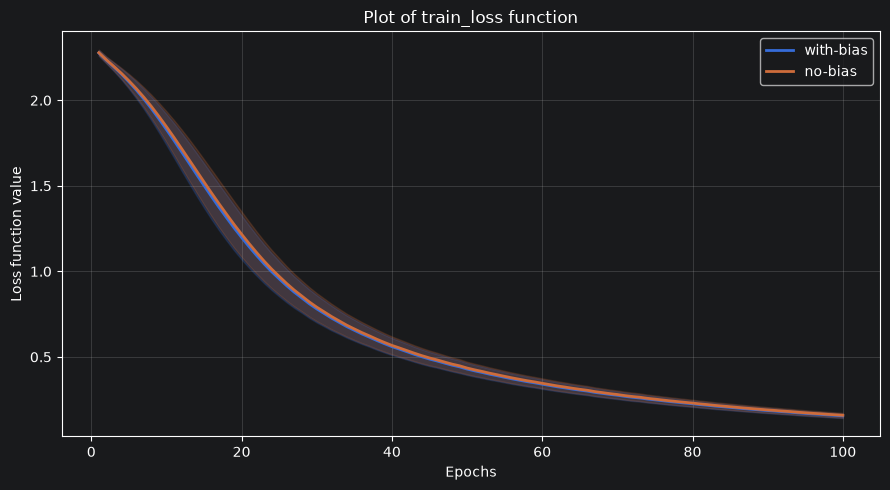

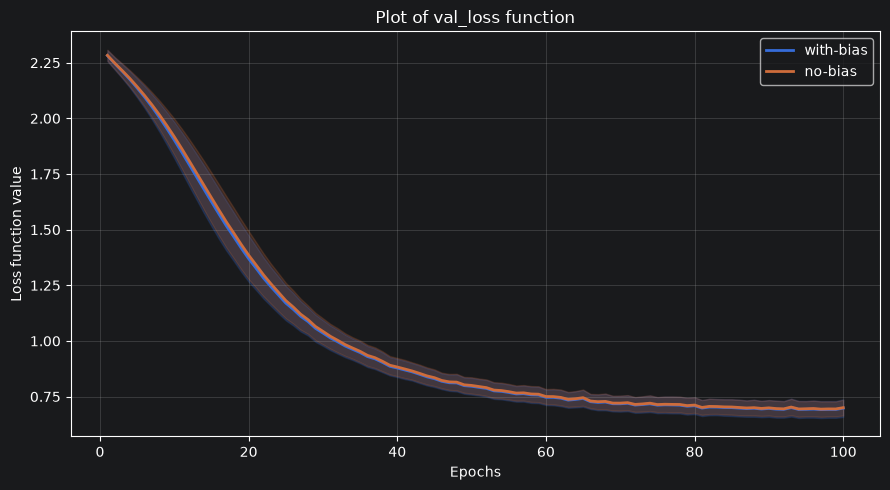

,config,loss_mean,loss_std,accuracy_mean,accuracy_std,precision_mean,precision_std,f1_score_mean,f1_score_std
0,with-bias,0.697974,0.039427,0.788333,0.018708,0.800362,0.018173,0.787365,0.019862
1,no-bias,0.700277,0.035099,0.790000,0.014337,0.801046,0.013125,0.788905,0.014860


In [35]:
trainings_hidden = {}

biases = {
    "with-bias": True,
    "no-bias": False,
}

for name, bias in biases.items():
    trainings_hidden[name] = cl_train.run_training(hidden_sizes=(32, 32), X_train=X_train, y_train=y_train, X_val=X_val,
                                            y_val=y_val, activation_hidden=ReLU(), epochs=100,
                                            loss_cls=CCELoss(), learning_rate=0.01, classes_count=10, if_bias=bias,)

cl_vs.plot_loss(trainings_hidden, "train_loss")
cl_vs.plot_loss(trainings_hidden, "val_loss")
display(cl_train.summarize_results(trainings_hidden))

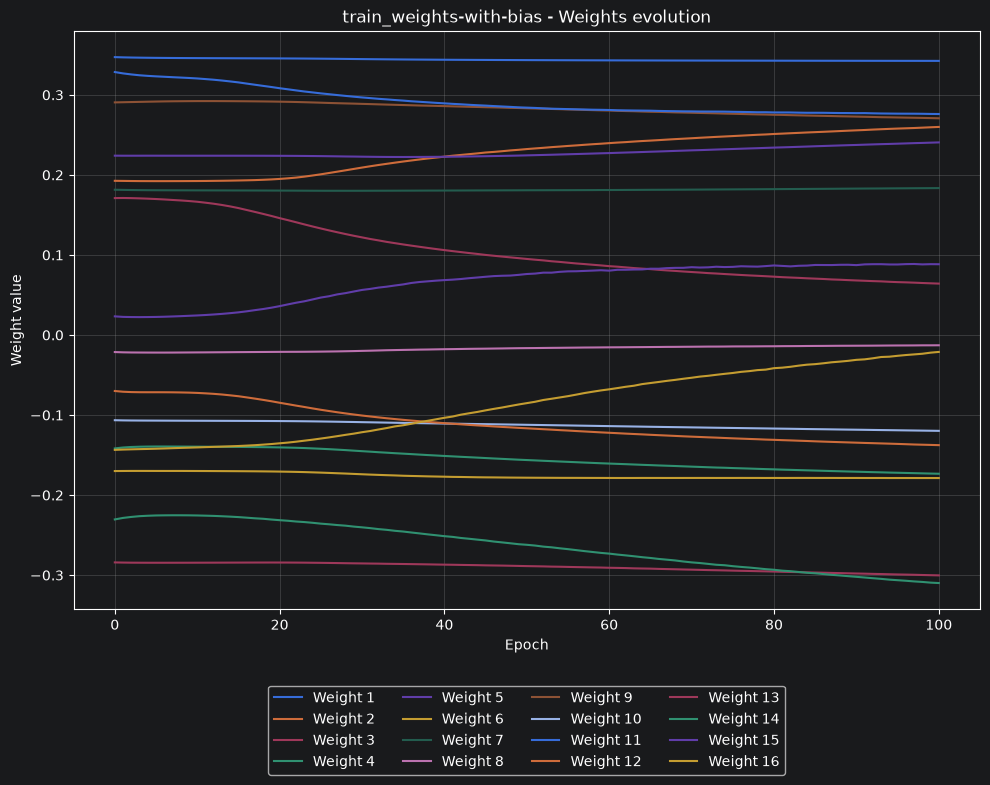

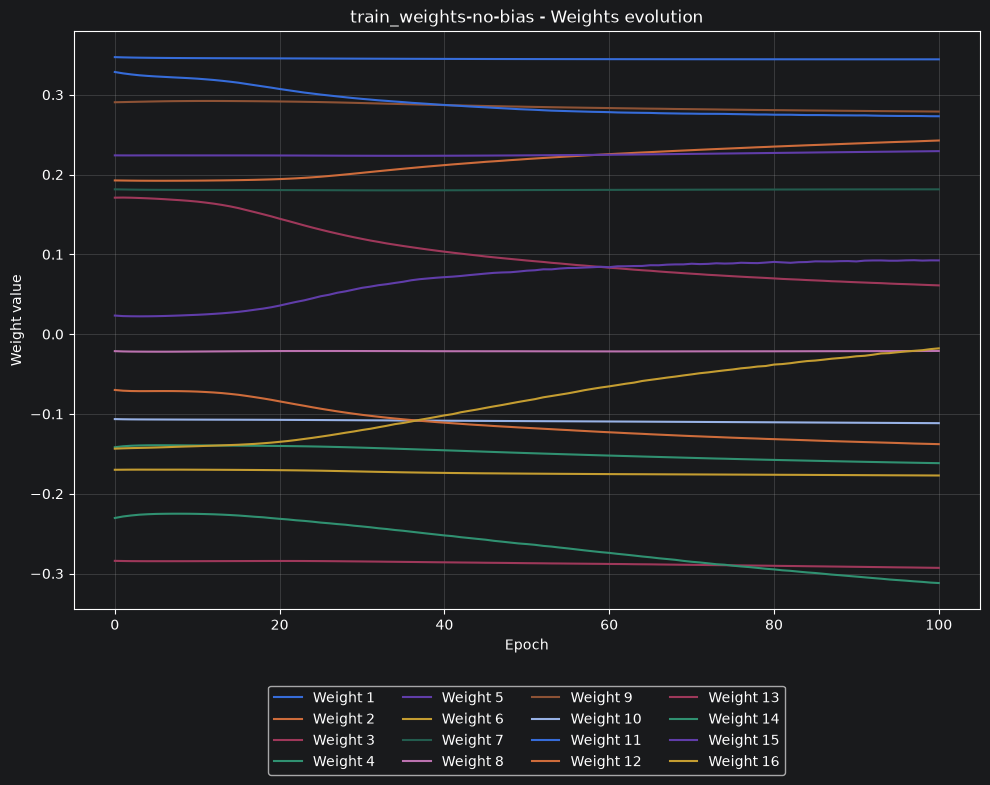

In [39]:
cl_vs.plot_weights(trainings_hidden["with-bias"][0]["history"], layer_idx=2,  type="train_weights-with-bias")
cl_vs.plot_weights(trainings_hidden["no-bias"][0]["history"], layer_idx=2,  type="train_weights-no-bias")


In [ ]:
trainings_hidden["yes-bias"][0]["history"]["weights"]